# **SYSTEM ANALISA DAN PREDIKSI KONSUMPSI NATURAL GAS PADA ANNEALING FURNACE PT.JSGI)**

### **A. Objektif**


Prediksi konsumsi natural gas adalah salah satu cara untuk menjaga profit perusahaan terhadap pemborosan utility comsuption natural gas. Prediksi konsumsi natural gas menggunakan data riwayat konsumsi natural gas pada setiap sepc produk dan algoritma untuk membangun sistem cerdas yang dapat menentukan nilai target senagai basis control management.


### **B. Menentukan Tujuan Teknis DS**

Prediksi konsumsi natural gas melibatkan analisis berbagai faktor, seperti spesifikasi produk ( Designation, Thickness, Width, Weight, Length ), Parameter produksi ( Annealing code, Line speed ) dan atribut relevan lainnya. Dengan memanfaatkan data historis dan menerapkan algoritme pembelajaran mesin, system dapat membuat model untuk menentukan nilai target untuk bulan selanjutnya.


### **C. Penyiapan dataset**

### Penjelasan data yang akan digunakan

Data yang akan digunakan adalah data record parameter produksi dan spesifikasi produk yang telah diproses secara aktual, data set yang digunakan adalah data selama 9 bulan, 2026-01-01 sampai 2026-09-30.
Target kolom yang akan diprediksi oleh system AI adalah kolom [ANLNG_FURNC_NATUAL_GAS_QT] = Jumlah natual gas yang digunakan untuk proses produksi 1 coil, dengan system ini diharapkan plan konsumsi natural gas akan dapat diprediksi secara akurat, yang selanjutnya nilai  prediksi akan digunakan sebagai nilai kontrol indikator normal.

### **1. Import pustaka (*library*) Python yang diperlukan**

In [390]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

### **2. Menyiapkan dataset, source data dari MES_DB**
Gunakan file berikut untuk gather data dari MES_DB :
"C:\Users\vb217249\OneDrive - PT.JFE Steel Galvanizing Indonesia\Training AI Engineer\PROJECT_AI\MES_Gather_data.py"

In [391]:
import pandas as pd

df = pd.read_csv(r"C:\Users\vb217249\OneDrive - PT.JFE Steel Galvanizing Indonesia\Training AI Engineer\PROJECT_AI\cgl_analysis_data.csv")

### 2.1 Menyiapkan data

In [392]:
# Menampilkan data fitur
print(df)

                      UPDAT_DT INLET_COIL_NO NO1_JSG_DESI_NM NO1_TRG_GRADE_CD  \
0      2026-01-03 10:03:25.425        KL7807         CC270DD              CCZ   
1      2026-01-03 11:08:34.975       KL78071         CC270DD              CCZ   
2      2026-01-03 12:11:08.798       KH72681         CA440WB              CCZ   
3      2026-01-03 13:23:15.422       KD69341          CA270D              CCZ   
4      2026-01-03 14:44:04.106       KD70362          CA270D              CCZ   
...                        ...           ...             ...              ...   
15761  2026-09-29 02:58:56.871        CS7206          CC590R              BBY   
15762  2026-09-29 03:14:39.640        CV6882          CC590R              BBY   
15763  2026-09-29 03:33:11.872        CV6782          CC590R              BBY   
15764  2026-09-29 03:49:59.574        CT5038          CC590R              BBY   
15765  2026-09-29 04:17:04.212        CT5004          CC590R              BBY   

       INLET_COIL_TH  INLET

### 2.2 Menelaah data

In [393]:
# Menampilkan nama kolom fitur
print(df.columns)

Index(['UPDAT_DT', 'INLET_COIL_NO', 'NO1_JSG_DESI_NM', 'NO1_TRG_GRADE_CD',
       'INLET_COIL_TH', 'INLET_COIL_WH', 'INLET_COIL_WT', 'INLET_COIL_LG',
       'LOGIC_LINE_CD', 'NO1_ANLNG_CD', 'AVE_CE_SP', 'DUMMY_SG', 'WORK_DT',
       'ANLNG_FURNC_NATUAL_GAS_QT'],
      dtype='str')


In [394]:
# Menampilkan data 5 baris teratas

print(df.head())

                  UPDAT_DT INLET_COIL_NO NO1_JSG_DESI_NM NO1_TRG_GRADE_CD  \
0  2026-01-03 10:03:25.425        KL7807         CC270DD              CCZ   
1  2026-01-03 11:08:34.975       KL78071         CC270DD              CCZ   
2  2026-01-03 12:11:08.798       KH72681         CA440WB              CCZ   
3  2026-01-03 13:23:15.422       KD69341          CA270D              CCZ   
4  2026-01-03 14:44:04.106       KD70362          CA270D              CCZ   

   INLET_COIL_TH  INLET_COIL_WH  INLET_COIL_WT  INLET_COIL_LG LOGIC_LINE_CD  \
0          0.696          957.0        16900.0         3232.0            A1   
1          0.696          957.0        13960.0         2223.0            A1   
2          0.984         1151.7         8920.0         1014.0            A1   
3          0.977         1267.4         7940.0          825.0            A1   
4          0.980         1275.0        12490.0         1284.0            A1   

   NO1_ANLNG_CD  AVE_CE_SP DUMMY_SG   WORK_DT  ANLNG_FURNC_NAT

In [395]:
# Informasi umum tentang dataset

print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 15766 entries, 0 to 15765
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   UPDAT_DT                   15766 non-null  str    
 1   INLET_COIL_NO              15766 non-null  str    
 2   NO1_JSG_DESI_NM            15766 non-null  str    
 3   NO1_TRG_GRADE_CD           15766 non-null  str    
 4   INLET_COIL_TH              15766 non-null  float64
 5   INLET_COIL_WH              15766 non-null  float64
 6   INLET_COIL_WT              15766 non-null  float64
 7   INLET_COIL_LG              15766 non-null  float64
 8   LOGIC_LINE_CD              15766 non-null  str    
 9   NO1_ANLNG_CD               15766 non-null  int64  
 10  AVE_CE_SP                  15750 non-null  float64
 11  DUMMY_SG                   858 non-null    str    
 12  WORK_DT                    15766 non-null  int64  
 13  ANLNG_FURNC_NATUAL_GAS_QT  15750 non-null  float64
dtypes

In [396]:
#Hapus kolom tidak terpakai
df = df.drop(columns=['DUMMY_SG', 'UPDAT_DT' , 'INLET_COIL_NO', 'WORK_DT', 'NO1_JSG_DESI_NM', 'NO1_TRG_GRADE_CD', 'LOGIC_LINE_CD'])

In [397]:
#Data terbaru setelah hapus kolom Dummy
print (df.head)

<bound method NDFrame.head of        INLET_COIL_TH  INLET_COIL_WH  INLET_COIL_WT  INLET_COIL_LG  \
0              0.696          957.0        16900.0         3232.0   
1              0.696          957.0        13960.0         2223.0   
2              0.984         1151.7         8920.0         1014.0   
3              0.977         1267.4         7940.0          825.0   
4              0.980         1275.0        12490.0         1284.0   
...              ...            ...            ...            ...   
15761          0.911         1240.0        20360.0         2295.0   
15762          1.010         1074.0        13590.0         1595.0   
15763          1.010         1040.0        19350.0         2346.0   
15764          1.190          975.0        19870.0         2181.0   
15765          1.190          975.0        19830.0         2177.0   

       NO1_ANLNG_CD  AVE_CE_SP  ANLNG_FURNC_NATUAL_GAS_QT  
0               750       22.0                       33.0  
1               750  

In [398]:
#Periksa row yang kososng
df.isnull()

,INLET_COIL_TH,INLET_COIL_WH,INLET_COIL_WT,INLET_COIL_LG,NO1_ANLNG_CD,AVE_CE_SP,ANLNG_FURNC_NATUAL_GAS_QT
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
15761,False,False,False,False,False,False,False
15762,False,False,False,False,False,False,False
15763,False,False,False,False,False,False,False
15764,False,False,False,False,False,False,False


### 2.3 Membersihkan Data

Mengisi nilai yang hilang jika ada, misalnya dengan menggunakan nilai mean, median atau modus.

Menghapus data yang tidak relevan atau outlier yang ekstrim.

In [399]:
# Menghapus semua baris yang memiliki cell kosong di DataFrame
df = df.dropna()

In [400]:
#Summaries posisi cell kosong
df.isnull().sum()

INLET_COIL_TH                0
INLET_COIL_WH                0
INLET_COIL_WT                0
INLET_COIL_LG                0
NO1_ANLNG_CD                 0
AVE_CE_SP                    0
ANLNG_FURNC_NATUAL_GAS_QT    0
dtype: int64

In [401]:
#Hapus data line speed <50mpm (abnormal)
df_cln = df[df['AVE_CE_SP']>49].copy()
print (df_cln)

       INLET_COIL_TH  INLET_COIL_WH  INLET_COIL_WT  INLET_COIL_LG  \
8              1.222         1395.7         9970.0          750.0   
9              1.221         1412.0        21440.0         1584.0   
10             1.140         1514.0         7320.0          545.0   
11             0.907         1576.6         7450.0          672.0   
12             0.995         1702.0        20770.0         1562.0   
...              ...            ...            ...            ...   
15761          0.911         1240.0        20360.0         2295.0   
15762          1.010         1074.0        13590.0         1595.0   
15763          1.010         1040.0        19350.0         2346.0   
15764          1.190          975.0        19870.0         2181.0   
15765          1.190          975.0        19830.0         2177.0   

       NO1_ANLNG_CD  AVE_CE_SP  ANLNG_FURNC_NATUAL_GAS_QT  
8               790       55.0                      226.0  
9               790       72.0                     

In [402]:
#Informasi data secara keseluruhan
print(df.describe())

       INLET_COIL_TH  INLET_COIL_WH  INLET_COIL_WT  INLET_COIL_LG  \
count   15750.000000   15750.000000   15750.000000   15750.000000   
mean        0.999880    1323.382781   18080.432063    2063.294476   
std         0.444772     249.102607    3240.694612     808.922802   
min         0.496000     800.000000    2970.000000     358.000000   
25%         0.643000    1140.000000   17370.000000    1383.000000   
50%         0.812000    1303.000000   18805.000000    2040.000000   
75%         1.218000    1542.000000   20140.000000    2644.000000   
max         2.650000    1827.000000   24790.000000    5246.000000   

       NO1_ANLNG_CD     AVE_CE_SP  ANLNG_FURNC_NATUAL_GAS_QT  
count  15750.000000  15750.000000               15750.000000  
mean     818.141587    117.096190                 351.069714  
std       42.688035     32.253948                 132.805158  
min      730.000000     10.000000                   0.000000  
25%      780.000000     92.000000                 312.000000  


In [403]:
#Cleaning outlier data consumprtion natural gas
col_target = 'ANLNG_FURNC_NATUAL_GAS_QT'
Q1 = df_cln[col_target].quantile(0.25)
Q3 = df_cln[col_target].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_cln = df_cln[(df_cln[col_target] >= lower_bound) &
                (df_cln[col_target] <= upper_bound)
                ]
print(f"jumlah baris setelah outier cleaning : {len(df_cln)}")


jumlah baris setelah outier cleaning : 14709


In [404]:
#Memuat fitur turunan Therma load untuk membantu model menangkap hubungan fisik konsumsi gas

df_cln['Thermal_Load'] = df_cln['INLET_COIL_WH'] * df_cln['INLET_COIL_TH'] * df_cln['AVE_CE_SP']
print (df_cln.head)

<bound method NDFrame.head of        INLET_COIL_TH  INLET_COIL_WH  INLET_COIL_WT  INLET_COIL_LG  \
8              1.222         1395.7         9970.0          750.0   
9              1.221         1412.0        21440.0         1584.0   
12             0.995         1702.0        20770.0         1562.0   
13             0.695         1622.0        19330.0         2184.0   
14             0.695         1622.0        19820.0         2239.0   
...              ...            ...            ...            ...   
15760          0.791         1145.8         7270.0         1036.0   
15762          1.010         1074.0        13590.0         1595.0   
15763          1.010         1040.0        19350.0         2346.0   
15764          1.190          975.0        19870.0         2181.0   
15765          1.190          975.0        19830.0         2177.0   

       NO1_ANLNG_CD  AVE_CE_SP  ANLNG_FURNC_NATUAL_GAS_QT  Thermal_Load  
8               790       55.0                      226.0    93804.

In [405]:
print (df_cln.columns)

Index(['INLET_COIL_TH', 'INLET_COIL_WH', 'INLET_COIL_WT', 'INLET_COIL_LG',
       'NO1_ANLNG_CD', 'AVE_CE_SP', 'ANLNG_FURNC_NATUAL_GAS_QT',
       'Thermal_Load'],
      dtype='str')


In [406]:
#Encoding Designaton & Taget grade

#df_encoded = pd.get_dummies(df_cln, columns=['NO1_JSG_DESI_NM', 'NO1_TRG_GRADE_CD', 'LOGIC_LINE_CD'], drop_first=True)
#print(f"Total kolom setelah encoding: {df_cln.shape[1]}")


### **SPLIT DATA UNTUK Trining 80% - Test 20%**

In [407]:
target_column = 'ANLNG_FURNC_NATUAL_GAS_QT'
X = df_cln.drop(columns=[target_column])
y = df_cln[target_column]

#Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Ukuran X_train: {X_train.shape}")
print(f"Ukuran X_test: {X_test.shape}")


Ukuran X_train: (11767, 7)
Ukuran X_test: (2942, 7)


### Scaling data menggunakan standard_scaller

In [408]:
scaler = StandardScaler()

#Fit dan transform hanya pada data training lalu transform pada data testing agar data mode tidak bocor
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


### **3.Exploratory Data Analysis (EDA)**

In [409]:
# Korelasi Data  melihat secara matrix correlasi setiap kolom
# Sangat penting di Linear Regression
# Bernilai (-) (0) (+)

df_cln.corr(numeric_only=True)

,INLET_COIL_TH,INLET_COIL_WH,INLET_COIL_WT,INLET_COIL_LG,NO1_ANLNG_CD,AVE_CE_SP,ANLNG_FURNC_NATUAL_GAS_QT,Thermal_Load
INLET_COIL_TH,1.000000,-0.391727,-0.194909,-0.815652,0.270097,-0.764057,-0.180024,0.421589
INLET_COIL_WH,-0.391727,1.000000,0.413060,0.026010,-0.388334,0.193558,-0.064650,0.359469
INLET_COIL_WT,-0.194909,0.413060,1.000000,0.355631,-0.096396,0.259626,0.563305,0.247901
INLET_COIL_LG,-0.815652,0.026010,0.355631,1.000000,-0.158259,0.749278,0.399764,-0.551339
NO1_ANLNG_CD,0.270097,-0.388334,-0.096396,-0.158259,1.000000,-0.216227,0.438524,-0.017933
AVE_CE_SP,-0.764057,0.193558,0.259626,0.749278,-0.216227,1.000000,0.091294,-0.026092
ANLNG_FURNC_NATUAL_GAS_QT,-0.180024,-0.064650,0.563305,0.399764,0.438524,0.091294,1.000000,-0.175551
Thermal_Load,0.421589,0.359469,0.247901,-0.551339,-0.017933,-0.026092,-0.175551,1.000000


In [410]:
df_cln.columns

Index(['INLET_COIL_TH', 'INLET_COIL_WH', 'INLET_COIL_WT', 'INLET_COIL_LG',
       'NO1_ANLNG_CD', 'AVE_CE_SP', 'ANLNG_FURNC_NATUAL_GAS_QT',
       'Thermal_Load'],
      dtype='str')

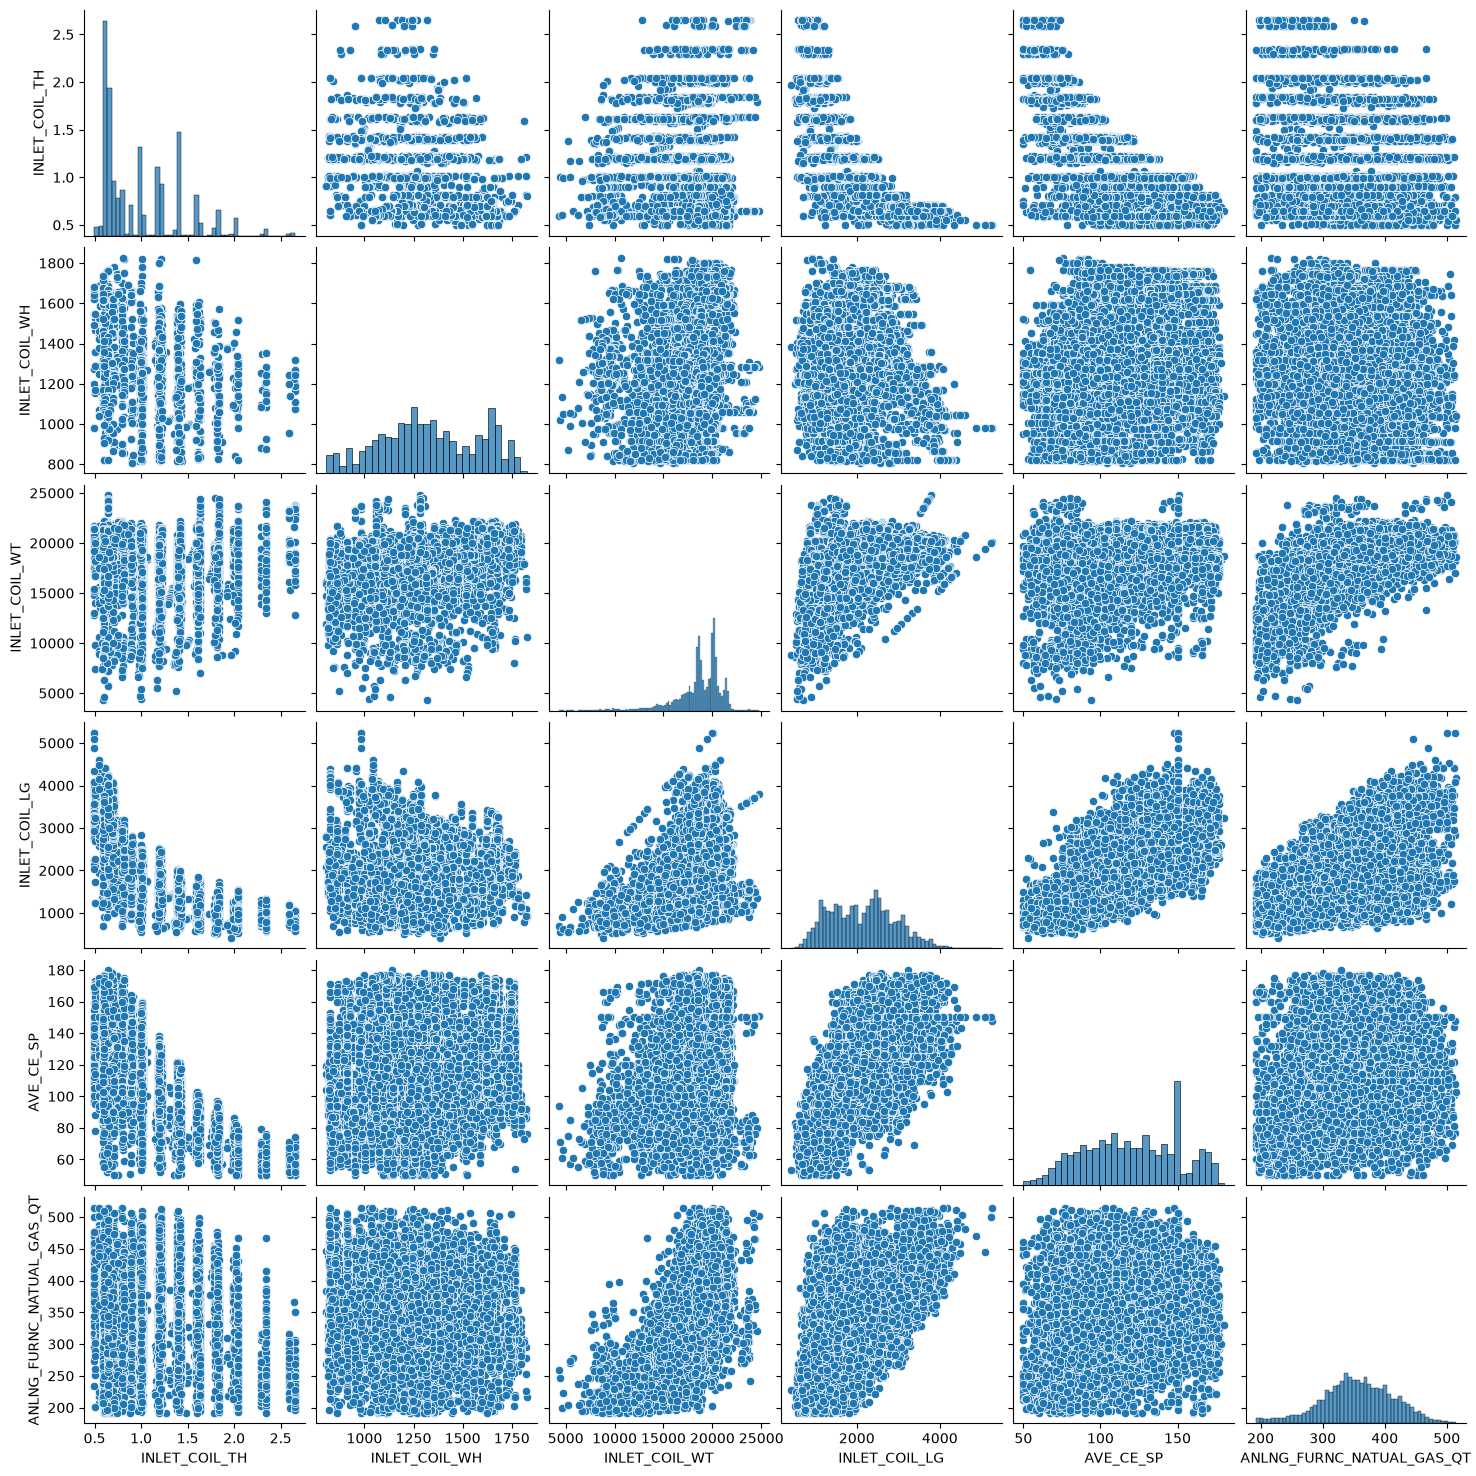

In [411]:
import seaborn as sns
import matplotlib.pyplot as plt

#Pilih kolom

cols = ["INLET_COIL_TH",
    "INLET_COIL_WH",
    "INLET_COIL_WT",
    "INLET_COIL_LG",
    "AVE_CE_SP",
    "ANLNG_FURNC_NATUAL_GAS_QT"
]

sns.pairplot(df_cln[cols], diag_kind="hist")
plt.show()

### **D. Model Training**

In [412]:
from sklearn.linear_model import LinearRegression

In [413]:
regression=LinearRegression()

In [414]:
regression.fit(X_train_scaled,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[-39.02,-22.07, 29.43,..., 25.93,-49.17, 26.28]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,355.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](7,)","[187.26,145.43,107.13,..., 79.9 , 23.14, 16.4 ]"


In [415]:
import joblib

# 1. Simpan model Linear Regression Anda
joblib.dump(regression, 'linear_regression_model.pkl')

# 2. Simpan scaler (StandardScaler) yang dipakai saat training
joblib.dump(scaler, 'scaler.pkl')

# 3. Simpan daftar kolom dari X_train (agar ukurannya pas sesuai kolom setelah get_dummies)
training_columns = X_train.columns.tolist()
joblib.dump(training_columns, 'training_columns.pkl')

print("Model, scaler, dan training_columns berhasil disimpan!")

Model, scaler, dan training_columns berhasil disimpan!


In [416]:
# Print the coefficients (slope) dan intercept

print(regression.coef_)

[-39.01851125 -22.07225035  29.43205758  36.87230683  25.9345424
 -49.16932455  26.277707  ]


In [417]:
print(regression.intercept_)

355.345457635761


In [418]:
# Parameter mana dari model yang sudah di-training

regression.get_params()

{'copy_X': True,
 'fit_intercept': True,
 'n_jobs': None,
 'positive': False,
 'tol': 1e-06}

In [419]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

#Prediksi data uji
y_pred = regression.predict(X_test_scaled)

#Evaluation matrix
r2 = r2_score(y_test, y_pred)
rsme = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"Performance model Regresi Linear:")
print(f"- R Score : {r2: .4f}")
print(f"- RSME    : {rsme: .2f}")
print(f"- MAE     : {mae: .2f}")


#Koefisien bobot tiap kolom
coefficients = pd.Series(regression.coef_, index=X.columns).sort_values(ascending=False)
print("\nKoefisien Pengaruh terhadap konsumsi gas:")
print(coefficients.head(10))

Performance model Regresi Linear:
- R Score :  0.7247
- RSME    :  30.89
- MAE     :  23.54

Koefisien Pengaruh terhadap konsumsi gas:
INLET_COIL_LG    36.872307
INLET_COIL_WT    29.432058
Thermal_Load     26.277707
NO1_ANLNG_CD     25.934542
INLET_COIL_WH   -22.072250
INLET_COIL_TH   -39.018511
AVE_CE_SP       -49.169325
dtype: float64


### **E. Prediction dengan data testing**

In [420]:
reg_pred=regression.predict(X_test_scaled)

In [421]:
reg_pred

array([348.64149789, 375.74638579, 391.80699352, ..., 230.74944375,
       387.38007979, 430.23815141], shape=(2942,))

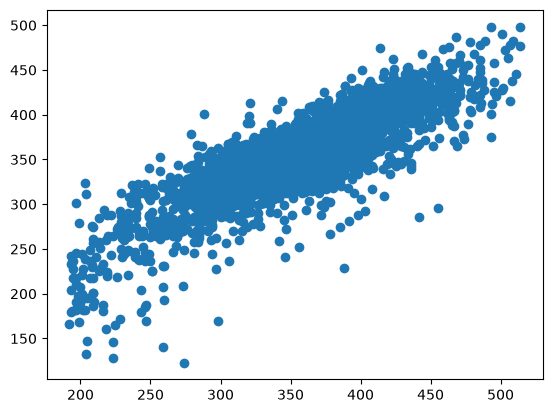

In [422]:
# Scatter plot hasil prediksi

plt.scatter(y_test,reg_pred)

In [423]:
# Residuals

residuals=y_test-reg_pred

In [424]:
residuals

9450    -34.641498
11855    28.253614
12932    27.193006
8335     -1.229350
2496     23.753594
           ...    
12955    32.445733
4564    -12.714204
2447     29.250556
13442   -40.380080
12972    18.761849
Name: ANLNG_FURNC_NATUAL_GAS_QT, Length: 2942, dtype: float64

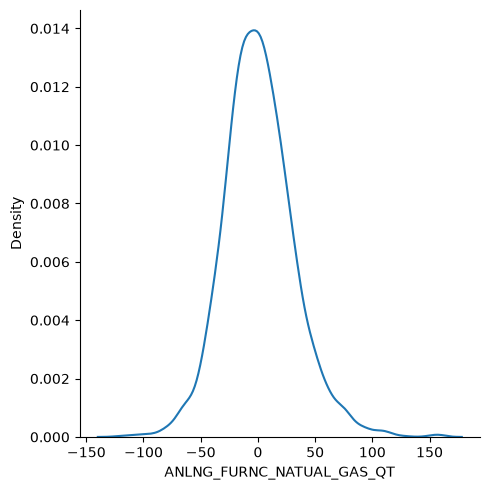

In [425]:
# Plot residuals

# sns.displot(residuals)
sns.displot(residuals,kind="kde")

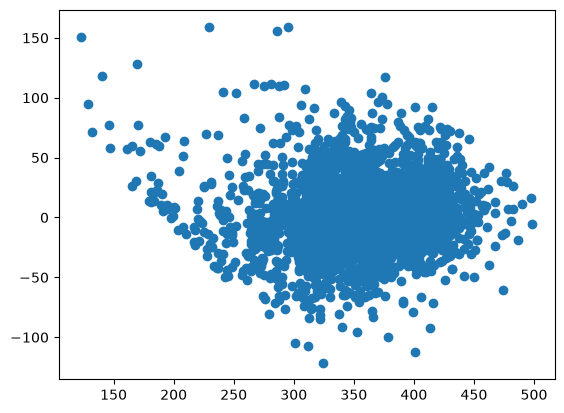

In [426]:
# Scatter plot with respect to prediction dan residuals
# Uniform distribution

plt.scatter(reg_pred,residuals)

In [427]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

print(mean_absolute_error(y_test,reg_pred))
print(mean_squared_error(y_test,reg_pred))
print(np.sqrt(mean_squared_error(y_test,reg_pred)))

23.54456693848222
954.049142179859
30.887685931125677


### **F. R Square dan Adjusted R Square**

Formula

R^2 = 1 - SSR/SST

R^2 = coefficient of determination SSR = sum of squares of residuals SST = total sum of squares

In [428]:
from sklearn.metrics import r2_score
score=r2_score(y_test,reg_pred)
print(score)

0.7247239774003833


Adjusted R2 = 1 - [(1-R2)*(n-1)/(n-k-1)]

where:

R2: The R2 of the model n: The number of observations k: The number of predictor variables.

In [429]:
# Display adjusted R-squared
1 - (1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

0.7240672179735949

### **G. Prediksi Data Baru**

In [430]:
target_column = 'ANLNG_FURNC_NATUAL_GAS_QT'

# Ambil fitur yang sama persis dengan training
data = df_cln.drop(
    columns=[target_column]
).reindex(
    columns=X_train.columns
).to_numpy(dtype=float)

# Periksa
print(data.shape)
print(data.dtype)

(14709, 7)
float64


In [431]:
data[0]

array([1.2220000e+00, 1.3957000e+03, 9.9700000e+03, 7.5000000e+02,
       7.9000000e+02, 5.5000000e+01, 9.3804997e+04])

In [432]:
data[0].shape

(7,)

In [433]:
data[0].reshape(1,-1)

array([[1.2220000e+00, 1.3957000e+03, 9.9700000e+03, 7.5000000e+02,
        7.9000000e+02, 5.5000000e+01, 9.3804997e+04]])

In [434]:
data[0].reshape(1,-1).shape

(1, 7)

In [435]:
# Transformation of new data (scaling)
scaled_data = scaler.transform(data[0].reshape(1, -1))

print(scaled_data)

[[ 0.55666463  0.26831605 -3.64165969 -1.79158522 -0.70385974 -2.13608897
  -1.42593643]]


c:\Users\vb217249\AppData\Local\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [436]:
# Ambil satu baris sebagai DataFrame
X_new = df_cln.drop(
    columns=['ANLNG_FURNC_NATUAL_GAS_QT']
).reindex(
    columns=X_train.columns
).iloc[[0]]

# Scaling dan prediksi
X_scaled = scaler.transform(X_new)
hasil = regression.predict(X_scaled)

print("Prediksi konsumsi gas:", hasil[0])

Prediksi konsumsi gas: 203.7669077752995


### **H. Pickling then model file for deployment**

In [437]:
### **H. Simpan Model, Scaler, dan Kolom untuk Deployment**
import joblib

# Simpan model Linear Regression
joblib.dump(regression, 'linear_regression_model.pkl')

# Simpan StandardScaler
joblib.dump(scaler, 'scaler.pkl')

# Simpan daftar kolom training (PENTING agar input sedikit dari aplikasi bisa dicocokkan)
training_columns = X_train.columns.tolist()
joblib.dump(training_columns, 'training_columns.pkl')

print("Semua file model (.pkl) dan training_columns.pkl berhasil disimpan!")

Semua file model (.pkl) dan training_columns.pkl berhasil disimpan!


# ***SELESAI ......***